In [1]:
import numpy as np
import sympy as sym
from sympy import symbols, Eq, pprint, init_printing
import scipy.integrate
import matplotlib.pyplot as plt
import tellurium as te
import json
import tellurium as te
from IPython.display import display
from publish_format import useLargeSize, useLargeSize2
sym.init_printing()

##### Cohesive network [PDS5, Wapl, Sororin, unloading]

In [2]:
## Rates
rates_coh = sym.symbols("K_RP_RPW, K_RPW_RP, K_RP_RPS, K_RPS_RP, K_RP_R, K_R_RP, K_RPW_R_free")
K_RP_RPW, K_RPW_RP, K_RP_RPS, K_RPS_RP, K_RP_R, K_R_RP, K_RPW_R_free = rates_coh

## Parameters, assume N_R = 1 (total number of RAD21 is 1)
parameters_coh = sym.symbols("tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R")
tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R = parameters_coh

rhs_coh = [ K_RPW_R_free * N_W * F_W - F_R_sister*N_R/tau_R,    # RAD21 unbinding
        F_W/(tau_W * (1-F_W)) - K_RP_RPW*(F_P*N_P - F_S*N_S - F_W*N_W), # Wapl binding 
        K_RPW_RP + K_RPW_R_free - 1/tau_W,              # Wapl unbinding  
        F_S/(tau_S * (1-F_S)) - K_RP_RPS * (F_P*N_P - F_S*N_S - F_W*N_W), # Sororin binding
        K_RPS_RP - 1/tau_S,      # Sororin unbinding
        F_P/(tau_P * (1-F_P)) - K_R_RP * (F_R_sister*N_R - F_P * N_P), # PDS5 binding
        K_RPW_R_free * F_W *N_W + K_RP_R*(F_P*N_P - F_S*N_S - F_W*N_W) - F_P*N_P/tau_P,   # PDS5 unbinding  
]

sol_rates_coh = sym.solve(rhs_coh, rates_coh)
# Print equations
for i, eq in enumerate(rhs_coh, 1):
    pprint(Eq(symbols(f"eq_{i}"), eq))

        F_R_sister⋅N_R                       
eq₁ = - ────────────── + F_W⋅K_RPW_R_free⋅N_W
             τ_R                             
           F_W                                              
eq₂ = ───────────── - K_RP_RPW⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_W⋅(1 - F_W)                                         
                                 1 
eq₃ = K_RPW_RP + K_RPW_R_free - ───
                                τ_W
           F_S                                              
eq₄ = ───────────── - K_RP_RPS⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_S⋅(1 - F_S)                                         
                  1 
eq₅ = K_RPS_RP - ───
                 τ_S
           F_P                                          
eq₆ = ───────────── - K_R_RP⋅(-F_P⋅N_P + F_R_sister⋅N_R)
      τ_P⋅(1 - F_P)                                     
        F_P⋅N_P                                                              
eq₇ = - ─────── + F_W⋅K_RPW_R_free⋅N_W + K_RP_R⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W

In [3]:
with open("parameters_12h.json", "r") as f:
    PARAMS = json.load(f)

In [4]:
def get_parameter_dict_coh(x, y):
    p = PARAMS["cohesive"]
    parameter_values_coh = [
        p["tau_S"],
        p["F_S"],
        p["N_S"],
        p["tau_W"],
        x / (p["x_offset_W"] + x),                        # modified F_W for sister
        p["N_W_base"] * (p["x_offset_W"] + x),            # modified N_W for sister
        p["tau_P"],
        y / (p["y_offset_P"] + y),                        # modified F_P for sister
        p["N_P_base"] * (p["y_offset_P"] + y),            # modified N_P for sister
        p["tau_R_sister"],
        p["F_R_sister"],
        p["N_R_modify"],                                 
    ]
    return dict(zip(parameters_coh, parameter_values_coh))

In [5]:
parameter_dict_coh = get_parameter_dict_coh(0.12028, 0.30274)
parameter_dict_coh


In [6]:
parameter_dict_coh

In [7]:
for s in sol_rates_coh.items():
    rate = s[1].evalf(subs=parameter_dict_coh)
    parameter_dict_coh[s[0]] = rate

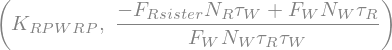

0.0219598058815098


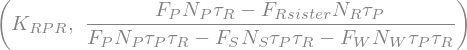

0.156633590950522


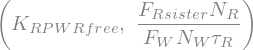

0.000262416340712407


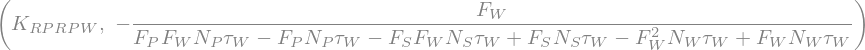

8.50586292019298e-7


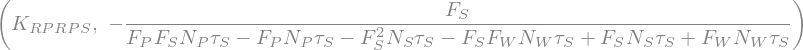

2.24085077555383e-6


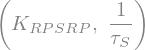

0.0100000000000000


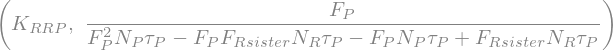

1.80588143214753e-7


In [8]:
for s in sol_rates_coh.items():
    rate = s[1].evalf(subs=parameter_dict_coh)
    parameter_dict_coh[s[0]] = rate
    display(s)
    print(rate)

#### Extrusive network [Nipbl, PDS5, Wapl, unloading]

In [9]:
## Rates
rates_ext = sym.symbols("Kext_Rfree_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_Rfree")
Kext_Rfree_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_Rfree = rates_ext

## Parameters, assume N_R = 1 (total number of RAD21 is 1)
parameters_ext = sym.symbols("tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext")
tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext = parameters_ext

rhs_ext = [ Kext_RN_R - 1 / tau_N_ext,  # NIPBL unbinding kinetics
        Kext_Rfree_RN * N_R_ext *(1-F_R_ext) + Kext_R_RN * (N_R_ext*F_R_ext - N_N_ext*F_N_ext - N_P_ext*F_P_ext) -  F_N_ext / tau_N_ext/ (1-F_N_ext), # NIPBL binding equilibrium
        Kext_RP_R * (N_P_ext * F_P_ext - N_W_ext * F_W_ext) + Kext_RPW_Rfree * N_W_ext * F_W_ext  - N_P_ext * F_P_ext/tau_P_ext, # PDS5 unbinding kinetics
        Kext_R_RP * (N_R_ext * F_R_ext - N_N_ext * F_N_ext - N_P_ext * F_P_ext)  - F_P_ext / tau_P_ext /(1-F_P_ext), # PDS5 binding equilibrium,
        Kext_RPW_RP + Kext_RPW_Rfree - 1 / tau_W_ext, # WAPL unbinding kinetics
        Kext_RP_RPW * (N_P_ext * F_P_ext - N_W_ext* F_W_ext)  - F_W_ext / tau_W_ext / (1-F_W_ext), # WAPL binding equilibrium
        Kext_RPW_Rfree * N_W_ext * F_W_ext - F_R_ext * N_R_ext / tau_R_ext,  # RAD21 unbinding kinetics
        Kext_Rfree_RN * N_N_ext * (1-F_N_ext) - F_R_ext / tau_R_ext / (1-F_R_ext) # RAD21 binding equilibrium, 
]

sol_rates_ext = sym.solve(rhs_ext, rates_ext)
# Print equations
for i, eq in enumerate(rhs_ext, 1):
    pprint(Eq(symbols(f"eq_{i}"), eq))

                     1   
eq₁ = Kext_RN_R - ───────
                  τ_N_ext
               F_N_ext                                                        
eq₂ = - ───────────────────── + Kext_R_RN⋅(-F_N_ext⋅N_N_ext - F_P_ext⋅N_P_ext 
        τ_N_ext⋅(1 - F_N_ext)                                                 

                                                        
+ F_R_ext⋅N_R_ext) + Kext_Rfree_RN⋅N_R_ext⋅(1 - F_R_ext)
                                                        
        F_P_ext⋅N_P_ext                                                       
eq₃ = - ─────────────── + F_W_ext⋅Kext_RPW_Rfree⋅N_W_ext + Kext_RP_R⋅(F_P_ext⋅
            τ_P_ext                                                           

                          
N_P_ext - F_W_ext⋅N_W_ext)
                          
               F_P_ext                                                        
eq₄ = - ───────────────────── + Kext_R_RP⋅(-F_N_ext⋅N_N_ext - F_P_ext⋅N_P_ext 
        τ_P_ext⋅(1 - F_P_ext)       

In [10]:
def get_parameter_dict_ext(x, y):
    p = PARAMS["extrusive"]
    parameter_values_ext = [
        p["tau_N"],
        p["F_N"],
        p["N_N"],
        p["tau_W"],
        (p["F_W_base"] - x) / (1 - x),                   # modified F_W for extrusive
        p["N_W_base"] * (1 - x),                          # modified N_W for extrusive
        p["tau_P"],
        (p["F_P_base"] - y) / (1 - y),                   # modified F_P for extrusive
        p["N_P_base"] * (1 - y),                          # modified N_P for extrusive
        p["tau_R_extrusive"],
        p["F_R_sister"],
        p["N_R_modify"],
    ]
    return dict(zip(parameters_ext, parameter_values_ext))


In [11]:
parameter_dict_ext = get_parameter_dict_ext(0.12028, 0.30274)
parameter_dict_ext 

In [12]:
for s in sol_rates_ext.items():
    rate = s[1].evalf(subs=parameter_dict_ext)
    parameter_dict_ext[s[0]] = rate

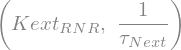

0.0125000000000000


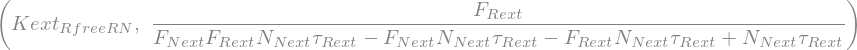

2.32824100460805e-8


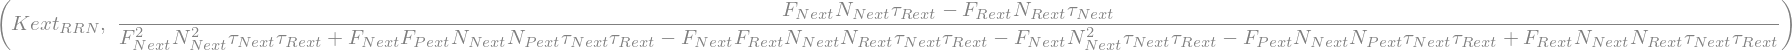

2.36316731037998e-7


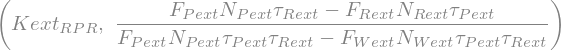

0.0261567749110340


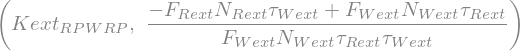

0.0123294505994469


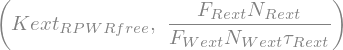

0.00989277162277536


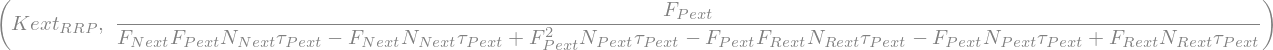

1.08326319566134e-7


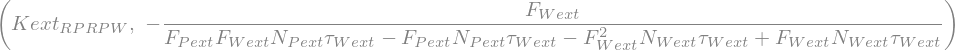

1.50924053602677e-6


In [13]:
for s in sol_rates_ext.items():
    rate = s[1].evalf(subs=parameter_dict_ext)
    parameter_dict_ext[s[0]] = rate
    display(s)
    print(rate)

In [14]:
model_coh  = '''
    # Define species and parameters
    R + P -> RP; K_R_RP*R*P - K_RP_R*RP
    RP + S -> RPS; K_RP_RPS*RP*S - K_RPS_RP*RPS
    RP + W -> RPW; K_RP_RPW*RP*W - K_RPW_RP*RPW
    RPW -> R_free + P + W; K_RPW_R_free*RPW 
    # Parameters
    K_RPS_RP = {K_RPS_RP}; 
    K_RP_RPS = {K_RP_RPS}; 
    K_RP_R = {K_RP_R}; 
    K_R_RP = {K_R_RP}; 
    K_RP_RPW = {K_RP_RPW}; 
    K_RPW_RP = {K_RPW_RP};  
    K_RPW_R_free = {K_RPW_R_free}; 
    R_free = {R_free_init}; 
    R = {R_init}; 
    RPW = {RPW_init}; 
    RPS = {RPS_init}; 
    RP = {RP_init}; 
    S = {S_init}; 
    W = {W_init}; 
    P = {P_init};
'''

def build_model(model_template, parameter_dict_coh):
    string_params = {str(k): v for k, v in parameter_dict_coh.items()}
    print(string_params)
    return model_template.format(**string_params)

In [15]:
parameter_dict_string_keys = {str(key): value for key, value in parameter_dict_coh.items()}
print(parameter_dict_string_keys)

# Define symbolic initial conditions
R_free_init, R_init, RPW_init, RPS_init, RP_init, S_init, W_init, P_init = sym.symbols(
    "R_free_init, R_init, RPW_init, RPS_init, RP_init, S_init, W_init, P_init")

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 43200, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219598058815098, 'K_RP_R': 0.156633590950522, 'K_RPW_R_free': 0.000262416340712407, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7}


In [16]:
init_conditions = {
    R_free_init: 0,
    R_init: parameter_dict_string_keys['N_R'],
    RPW_init: 0,
    RPS_init: 0,
    RP_init: 0,
    S_init: parameter_dict_string_keys['N_S'],
    W_init:  parameter_dict_string_keys['N_W'],
    P_init: parameter_dict_string_keys['N_P'],
}

In [17]:
parameter_dict = parameter_dict_coh | init_conditions
parameter_dict_string_keys = {str(key): value for key, value in parameter_dict.items()}

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 43200, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219598058815098, 'K_RP_R': 0.156633590950522, 'K_RPW_R_free': 0.000262416340712407, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 53566.811760000004, 'P_init': 159436.0851}

    # Define species and parameters
    R + P -> RP; K_R_RP*R*P - K_RP_R*RP
    RP + S -> RPS; K_RP_RPS*RP*S - K_RPS_RP*RPS
    RP + W -> RPW; K_RP_RPW*RP*W - K_RPW_RP*RPW
    RPW -> R_free + P + W; K_RPW_R_free*RPW 
    # Parameters
    K_RPS_RP = 0.0100000000000000; 
    K_RP_RPS = 0.00000224085077555383; 
    K_RP_R = 0.156633590950522; 
    K_R_RP = 1.80588143214753E-7; 
    

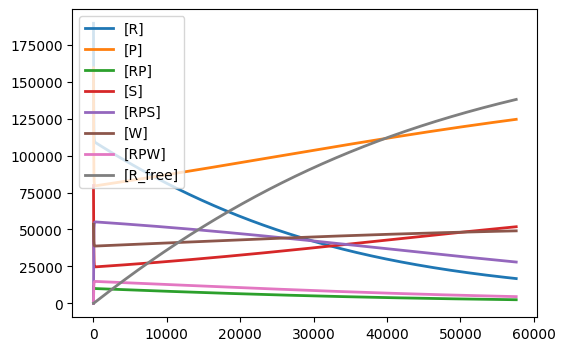

In [18]:
model = build_model(model_coh, parameter_dict_string_keys)
print(model)
# Load the modes
r = te.loada(model)
# Simulate the model
Model_WT = r.simulate(0, 3600*16, 100000)
# Plot the simulation results
r.plot()

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 43200, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219598058815098, 'K_RP_R': 0.156633590950522, 'K_RPW_R_free': 0.000262416340712407, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 53566.811760000004, 'P_init': 159436.0851}
{tau_S: 100.0, F_S: 0.52, N_S: 79770, tau_W: 45.0, F_W: 0.15615101002232953, N_W: 53566.811760000004, tau_P: 72, F_P: 0.34295489045472055, N_P: 159436.0851, tau_R: 43200, F_R_sister: 0.5, N_R: 189646.666667, K_RPW_RP: 0.0219598058815098, K_RP_R: 0.156633590950522, K_RPW_R_free: 0.000262416340712407, K_RP_RPW: 8.50586292019298e-7, K_RP_RPS: 2.24085077555383e-6, K_RPS_RP: 0.01000000

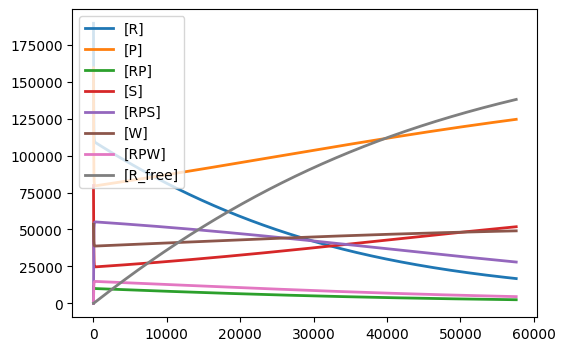

In [19]:
parameter_dict_string_keys = {str(key): value for key, value in parameter_dict.items()}
print(parameter_dict_string_keys)
model = '''
    # Define species and parameters
    R + P ->  RP; K_R_RP*R*P - K_RP_R*RP
    RP + S -> RPS; K_RP_RPS*RP*S - K_RPS_RP*RPS
    RP + W -> RPW; K_RP_RPW*RP*W - K_RPW_RP*RPW
    RPW -> R_free + P + W; K_RPW_R_free*RPW 
    # Parameters
    K_RPS_RP = {K_RPS_RP}; K_RP_RPS = {K_RP_RPS}; K_RP_R = {K_RP_R}; K_R_RP = {K_R_RP}; 
    K_RP_RPW = {K_RP_RPW}; K_RPW_RP = {K_RPW_RP};  K_RPW_R_free = {K_RPW_R_free}; 
    R_free = 0; R = {N_R}; RPW = 0; RPS = 0; RP=0; 
    S = {N_S}; W = {N_W}; P={N_P};
    '''.format(**parameter_dict_string_keys)

print(parameter_dict)
# Load the modes
r = te.loada(model)

# Simulate the model
Model_WT = r.simulate(0, 3600*16, 100000)

# Plot the simulation results
r.plot()

### define the quantify of interest

In [20]:
def RAD21_bound_time(K_RPW_R_free, B_W, F_R_free, N_R):
    # K_RPW_R_free * N_W * F_W - F_R_sister/tau_R
    ### F_R is the fraction of bounded RAD21, T_W is the total number of bounded Wapl 
    return (N_R - F_R_free)/(K_RPW_R_free * B_W)

RAD21_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], B_W = r.RPW_conc, F_R_free=r.R_free_conc, N_R = parameter_dict[N_R])

In [21]:
def Wapl_bound_time(K_RPW_RP, K_RPW_R_free):
    # K_RPW_RP + K_RPW_R_free - 1/tau_W, wapl unbinding 
    return 1/(K_RPW_R_free + K_RPW_RP)

def Wapl_bound_fraction(tau_W, K_RP_RPW, RP):
    # F_W/(tau_W * (1-F_W)) - K_RP_RPW*(F_P*N_P - F_S*N_S - F_W*N_W), # Wapl binding 
    temp = tau_W*K_RP_RPW*RP
    return temp/(1+temp)

tau_W = Wapl_bound_time(K_RPW_RP = parameter_dict[K_RPW_RP], K_RPW_R_free = parameter_dict[K_RPW_R_free])
F_W = Wapl_bound_fraction(tau_W = tau_W, K_RP_RPW = parameter_dict[K_RP_RPW], RP=r.RP_conc)
print(tau_W)
print(F_W)

45.0000000000000
0.0841459083284468


In [22]:
def Sororin_bound_time(K_RPS_RP):
    # K_RPS_RP - 1/tau_S,   #Sororin unbinding
    return 1/(K_RPS_RP)

def Sororin_bound_fraction(tau_S, K_RP_RPS, RP):
    # F_S/(tau_S * (1-F_S)) - K_RP_RPS * (F_P*N_P - F_S*N_S - F_W*N_W), # Sororin binding
    temp = tau_S*K_RP_RPS*RP
    return temp/(1+temp)

tau_S = Sororin_bound_time(K_RPS_RP = parameter_dict[K_RPS_RP])
F_S =  Sororin_bound_fraction(tau_S, K_RP_RPS=parameter_dict[K_RP_RPS], RP=r.RP_conc)
print(tau_S)
print(F_S)

100.000000000000
0.349755966679286


In [23]:
def PDS5_bound_time(K_RPW_R_free, K_RP_R, RP, W_bound, P_bound):
    # K_RPW_R_free * F_W *N_W + K_RP_R*(F_P*N_P - F_S*N_S - F_W*N_W) - F_P*N_P/tau_P,   # PDS5 unbinding  
    return P_bound/(K_RPW_R_free * W_bound +  K_RP_R * RP)

def PDS5_bound_fraction(tau_P, K_R_RP, R):
    # F_P/(tau_P * (1-F_P)) - K_R_RP * (F_R_sister - F_P * N_P), # PDS5 binding
    temp = tau_P * K_R_RP * R
    return temp/(1+temp)

tau_P = PDS5_bound_time(K_RPW_R_free = parameter_dict[K_RPW_R_free], K_RP_R = parameter_dict[K_RP_R], RP=r.RP_conc, W_bound=r.RPW_conc, P_bound=(r.RP_conc+r.RPW_conc+r.RPS_conc))
F_P = PDS5_bound_fraction(tau_P = tau_P, K_R_RP = parameter_dict[K_R_RP], R = r.R_conc)
print(tau_P)
print(F_P)

92.3838658435764
0.218246589289442


### Depletion of Sororin

In [36]:
parameter_dict_string_keys = {str(key): value for key, value in parameter_dict.items()}
print(parameter_dict_string_keys)
# Define ranges for K_SX (from S to X) and N_X
# N_S_values = np.logspace(-10, 0, 10)
N_S_values = [i * parameter_dict[N_S] for i in [0, 0.1, 1, 1.1, 1.5, 2, 10, 20]]
# Initialize an empty matrix to store bound_time values
bound_time_matrix = np.zeros(len(N_S_values))

all_bound_RAD21 = []
all_sep_RAD21 = []
all_time_RAD21 = []
all_time = None  # time is same for all runs

for i, N_S_val in enumerate(N_S_values):
    # simulated WT five-state model
    parameter_dict_string_keys.update({'S_init':  N_S_val})
    model = build_model(model_coh, parameter_dict_string_keys)
    # Load the model
    r = te.loada(model)
    # Simulate the model
    Model_dSororin = r.simulate(0, 3600*16, 100000)

    # Compute bound RAD21
    bound_RAD21 = (parameter_dict[N_R] - Model_dSororin[:, 8]) / parameter_dict[N_R]
    sep_RAD21 = 800/Model_dSororin[:, 8]
    time_RAD21 = RAD21_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], B_W = r.RPW_conc, F_R_free=r.R_free_conc, N_R = parameter_dict[N_R])

    all_bound_RAD21.append(bound_RAD21)
    all_sep_RAD21.append(sep_RAD21)
    all_time_RAD21.append(time_RAD21)
    # Save time once
    if all_time is None:
        all_time = Model_dSororin[:, 0] / 3600
    
# update the paras back 
parameter_dict_string_keys.update({'S_init':  parameter_dict[N_S]}) 

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 43200, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219598058815098, 'K_RP_R': 0.156633590950522, 'K_RPW_R_free': 0.000262416340712407, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 53566.811760000004, 'P_init': 159436.0851}
{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 43200, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219598058815098, 'K_RP_R': 0.156633590950522, 'K_RPW_R_free': 0.000262416340712407, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085

/var/folders/lx/fhbfjbg11w929k0p_rgg61ch0000gn/T/ipykernel_35477/988664535.py:25: RuntimeWarning:

divide by zero encountered in divide



{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 43200, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219598058815098, 'K_RP_R': 0.156633590950522, 'K_RPW_R_free': 0.000262416340712407, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 53566.811760000004, 'P_init': 159436.0851}
{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 43200, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219598058815098, 'K_RP_R': 0.156633590950522, 'K_RPW_R_free': 0.000262416340712407, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085

In [38]:
all_time_RAD21
result = [x / 3600 for x in all_time_RAD21]
result


In [41]:
result[2]/result[0]

In [40]:
result[-1]/result[2]

In [44]:
Model_dSororin[:, 8][-1]/800, bound_RAD21

(34.13381886718785,
 [1.         0.99999999 0.99999995 ... 0.85601365 0.85601227 0.85601089])

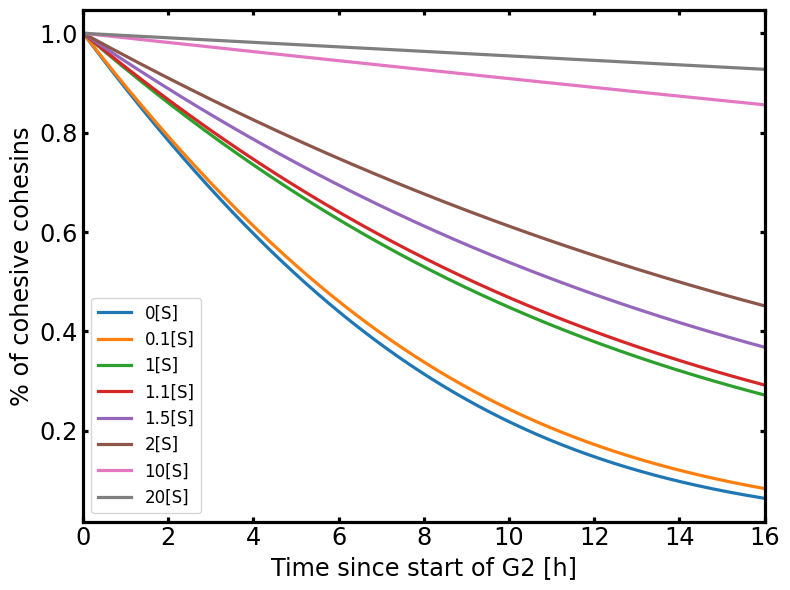

In [29]:
fig, ax1 = plt.subplots(figsize=(8, 6))
plt.rcParams['svg.fonttype'] = 'none'

ratios = [0, 0.1, 1, 1.1, 1.5, 2, 10, 20]
N_S_values = [r * parameter_dict[N_S] for r in ratios]

for i, bound_RAD21 in enumerate(all_bound_RAD21):
    ax1.plot(
        all_time,
        bound_RAD21,
        label = f'{ratios[i]}[S]'
    )

    final_sep =  parameter_dict[N_R] * bound_RAD21[-1] / 800 


ax1.set_xlim([all_time[0], all_time[-1]])
ax1.set_xlabel("Time since start of G2 [h]")
ax1.set_ylabel("% of cohesive cohesins")
ax1.legend(fontsize=12)

# Right axis
# ax2 = ax1.twinx()
# y1_min, y1_max = ax1.get_ylim()
# ax2.set_ylim(y1_min*800, y1_max*800)
# ax2.set_ylabel('Separation [Mb]')
useLargeSize2(plt, ax1, marker_lines = None, fontsize = 'xx-large', fontproperties=None, LW=2.3)
# plt.savefig("sisterCs_plot.svg", format='svg')
plt.show()
# plt.savefig("sisterCs_plot.svg", format='svg')

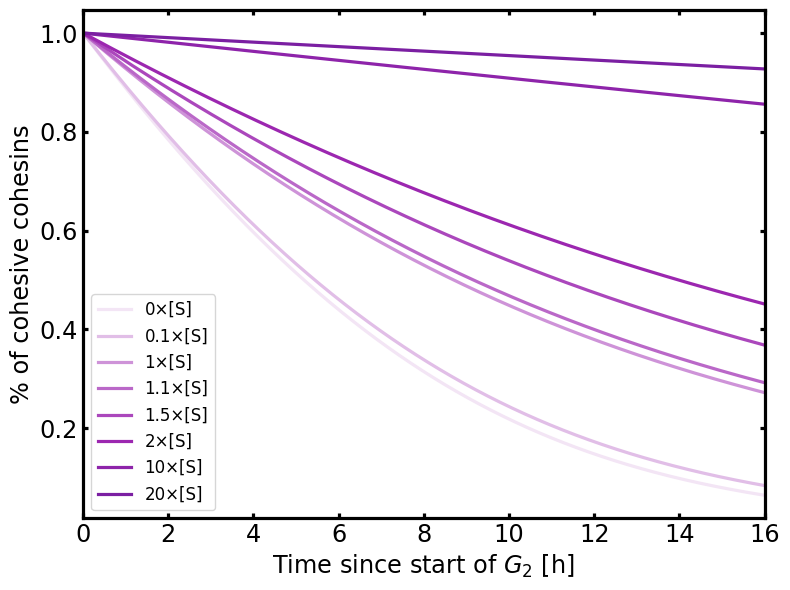

In [35]:
ratios = [0, 0.1, 1, 1.1, 1.5, 2, 10, 20]
colors = ['#F3E5F5', '#E1BEE7', '#CE93D8', '#BA68C8', '#AB47BC', '#9C27B0', '#8E24AA', '#7B1FA2', '#6A1B9A', '#4A148C']
import matplotlib.cm as cm
fig, ax1 = plt.subplots(figsize=(8, 6))


colors = cm.RdBu_r(np.linspace(0, 1, len(ratios)))

colors = ['#F3E5F5', '#E1BEE7', '#CE93D8', '#BA68C8', '#AB47BC', '#9C27B0', '#8E24AA', '#7B1FA2', '#6A1B9A', '#4A148C']
for i, bound_RAD21 in enumerate(all_bound_RAD21):
    ax1.plot(
        all_time,
        bound_RAD21,
        color=colors[i],
        label=f'{ratios[i]}×[S]'
    )
    final_sep = parameter_dict[N_R] * bound_RAD21[-1] / 800

ax1.set_xlim([all_time[0], all_time[-1]])
ax1.set_xlabel(r"Time since start of $G_2$ [h]", fontsize=20)
ax1.set_ylabel("% of cohesive cohesins", fontsize=20)
ax1.legend(fontsize=12)

useLargeSize2(plt, ax1, marker_lines = None, fontsize = 'xx-large', fontproperties=None, LW=2.3)
# plt.title("% sisterCs vs [S]", fontsize=20)
# plt.savefig("sisterCs_plot.svg", format='svg')
plt.show()

### dWapl

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 36000, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219073226133673, 'K_RP_R': 0.156542785420589, 'K_RPW_R_free': 0.000314899608854888, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 2678.3405880000005, 'P_init': 159436.0851}

    # Define species and parameters
    R + P -> RP; K_R_RP*R*P - K_RP_R*RP
    RP + S -> RPS; K_RP_RPS*RP*S - K_RPS_RP*RPS
    RP + W -> RPW; K_RP_RPW*RP*W - K_RPW_RP*RPW
    RPW -> R_free + P + W; K_RPW_R_free*RPW 
    # Parameters
    K_RPS_RP = 0.0100000000000000; 
    K_RP_RPS = 0.00000224085077555383; 
    K_RP_R = 0.156542785420589; 
    K_R_RP = 1.80588143214753E-7; 
    

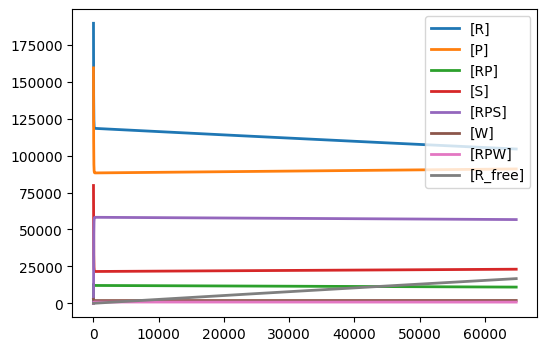

Cohesin Bound Time: 688114.453861014
Wapl Time: 45.0000000000000, Wapl Bound Fraction: 0.288804116096732
Sororin Time: 100.000000000000, Sororin Bound Fraction: 0.703911340187936
PDS5 Time: 40.6579829912254, PDS5 Bound Fraction: 0.423577357653478
{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 36000, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219073226133673, 'K_RP_R': 0.156542785420589, 'K_RPW_R_free': 0.000314899608854888, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 5356.681176000001, 'P_init': 159436.0851}

    # Define species and parameters
    R + P -> RP; K_R_RP*R*P - K_RP_R*RP
    RP + S -> RPS; K_RP_RPS*RP*S - K_RPS_RP*RPS
    RP + W -

In [56]:
# Define ranges for K_SX (from S to X) and N_X
# N_S_values = np.logspace(-10, 0, 10)
N_W_values = [i * parameter_dict[N_W] for i in [0.05, 0.1, 0.2, 0.3, 1]]
# Initialize an empty matrix to store bound_time values
bound_time_matrix = np.zeros(len(N_W_values))

for i, N_W_val in enumerate(N_W_values):
    # simulated WT five-state model
    parameter_dict_string_keys["W_init"] = N_W_val
    model = build_model(model_coh, parameter_dict_string_keys)
    print(model)
    # Load the model
    r = te.loada(model)
    # Simulate the model
    if i==0:
        r = te.loada(model)
        Model_dWapl = r.simulate(0, 3600*18, 100000)
        r.plot()
    
    r.simulate(0, 3600*6, 100000)
    bound_time1 = RAD21_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], B_W = r.RPW_conc, F_R_free=r.R_free_conc, N_R = parameter_dict[N_R])
    
    tau_W = Wapl_bound_time(K_RPW_RP = parameter_dict[K_RPW_RP], K_RPW_R_free = parameter_dict[K_RPW_R_free])
    fraction_W = Wapl_bound_fraction(tau_W = tau_W, K_RP_RPW = parameter_dict[K_RP_RPW], RP=r.RP_conc)

    tau_S = Sororin_bound_time(K_RPS_RP = parameter_dict[K_RPS_RP])
    fraction_S =  Sororin_bound_fraction(tau_S, K_RP_RPS=parameter_dict[K_RP_RPS], RP=r.RP_conc)

    tau_P = PDS5_bound_time(K_RPW_R_free = parameter_dict[K_RPW_R_free], K_RP_R = parameter_dict[K_RP_R], RP=r.RP_conc, W_bound=r.RPW_conc, P_bound=(r.RP_conc+r.RPW_conc+r.RPS_conc))
    fraction_P = PDS5_bound_fraction(tau_P = tau_P, K_R_RP = parameter_dict[K_R_RP], R = r.R_conc)
    
    print("Cohesin Bound Time: {}".format(bound_time1))
    print("Wapl Time: {}, Wapl Bound Fraction: {}".format(tau_W, fraction_W))
    print("Sororin Time: {}, Sororin Bound Fraction: {}".format(tau_S, fraction_S))
    print("PDS5 Time: {}, PDS5 Bound Fraction: {}".format(tau_P, fraction_P))

parameter_dict_string_keys.update({'W_init':  parameter_dict[N_W]}) 

## dWapl, dSororin

In [57]:
# Define ranges for K_SX (from S to X) and N_X
# N_S_values = np.logspace(-10, 0, 10)
N_S_values = [0.05*parameter_dict[N_S]]
N_W_values = [0.05*parameter_dict[N_W]]
# Initialize an empty matrix to store bound_time values
bound_time_matrix = np.zeros((len(N_S_values), len(N_W_values)))

for i, N_S_val in enumerate(N_S_values):
    for j, N_W_val in enumerate(N_W_values): 
        # simulated WT five-state mode
        parameter_dict_string_keys["S_init"] = N_S_val
        parameter_dict_string_keys["W_init"] = N_W_val
        model = build_model(model_coh, parameter_dict_string_keys)
        # Load the model
        if i==0:
            r = te.loada(model)
            Model_dWdS = r.simulate(0, 3600*18, 100000)
        r = te.loada(model)
  
        r.simulate(0, 3600*6, 10000)
        bound_time1 = RAD21_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], B_W = r.RPW_conc, F_R_free=r.R_free_conc, N_R = parameter_dict[N_R])
    
        tau_W = Wapl_bound_time(K_RPW_RP = parameter_dict[K_RPW_RP], K_RPW_R_free = parameter_dict[K_RPW_R_free])
        fraction_W = Wapl_bound_fraction(tau_W = tau_W, K_RP_RPW = parameter_dict[K_RP_RPW], RP=r.RP_conc)

        tau_S = Sororin_bound_time(K_RPS_RP = parameter_dict[K_RPS_RP])
        fraction_S =  Sororin_bound_fraction(tau_S, K_RP_RPS=parameter_dict[K_RP_RPS], RP=r.RP_conc)

        tau_P = PDS5_bound_time(K_RPW_R_free = parameter_dict[K_RPW_R_free], K_RP_R = parameter_dict[K_RP_R], RP=r.RP_conc, W_bound=r.RPW_conc, P_bound=(r.RP_conc+r.RPW_conc+r.RPS_conc))
        fraction_P = PDS5_bound_fraction(tau_P = tau_P, K_R_RP = parameter_dict[K_R_RP], R = r.R_conc)

        print("Cohesin Bound Time: {}".format(bound_time1))
        print("Wapl Time: {}, Wapl Bound Fraction: {}".format(tau_W, fraction_W))
        print("Sororin Time: {}, Sororin Bound Fraction: {}".format(tau_S, fraction_S))
        print("PDS5 Time: {}, PDS5 Bound Fraction: {}".format(tau_P, fraction_P))

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 36000, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219073226133673, 'K_RP_R': 0.156542785420589, 'K_RPW_R_free': 0.000314899608854888, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 3988.5, 'W_init': 2678.3405880000005, 'P_init': 159436.0851}
Cohesin Bound Time: 455779.308077795
Wapl Time: 45.0000000000000, Wapl Bound Fraction: 0.470808935313820
Sororin Time: 100.000000000000, Sororin Bound Fraction: 0.838930986676718
PDS5 Time: 7.65337120048238, PDS5 Bound Fraction: 0.174680032901920


## dPDS5

In [58]:
parameter_dict_string_keys = {str(key): value for key, value in parameter_dict.items()}
print(parameter_dict_string_keys)
import tellurium as te

# Define ranges for K_SX (from S to X) and N_X
# N_S_values = np.logspace(-10, 0, 10)
N_P_values = [i * parameter_dict[N_P] for i in [0.05, 0.1, 0.2, 0.3, 1]]
# Initialize an empty matrix to store bound_time values
bound_time_matrix = np.zeros(len(N_P_values))

for i, N_P_val in enumerate(N_P_values):
    # simulated WT five-state mode
    parameter_dict_string_keys["P_init"] = N_P_val
    model = build_model(model_coh, parameter_dict_string_keys)
    # Load the model
    r = te.loada(model)
    # Simulate the modes
    ## 
    if i==0:
        r = te.loada(model)
        Model_dPDS5 = r.simulate(0, 3600*18, 100000)

    r.simulate(0, 3600*6, 10000)
    bound_time1 = RAD21_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], B_W = r.RPW_conc, F_R_free=r.R_free_conc, N_R = parameter_dict[N_R])
    
    tau_W = Wapl_bound_time(K_RPW_RP = parameter_dict[K_RPW_RP], K_RPW_R_free = parameter_dict[K_RPW_R_free])
    fraction_W = Wapl_bound_fraction(tau_W = tau_W, K_RP_RPW = parameter_dict[K_RP_RPW], RP=r.RP_conc)

    tau_S = Sororin_bound_time(K_RPS_RP = parameter_dict[K_RPS_RP])
    fraction_S =  Sororin_bound_fraction(tau_S, K_RP_RPS=parameter_dict[K_RP_RPS], RP=r.RP_conc)

    tau_P = PDS5_bound_time(K_RPW_R_free = parameter_dict[K_RPW_R_free], K_RP_R = parameter_dict[K_RP_R], RP=r.RP_conc, W_bound=r.RPW_conc, P_bound=(r.RP_conc+r.RPW_conc+r.RPS_conc))
    fraction_P = PDS5_bound_fraction(tau_P = tau_P, K_R_RP = parameter_dict[K_R_RP], R = r.R_conc)
    
    print("Cohesin Bound Time: {}".format(bound_time1))
    print("Wapl Time: {}, Wapl Bound Fraction: {}".format(tau_W, fraction_W))
    print("Sororin Time: {}, Sororin Bound Fraction: {}".format(tau_S, fraction_S))
    print("PDS5 Time: {}, PDS5 Bound Fraction: {}".format(tau_P, fraction_P))

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 36000, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219073226133673, 'K_RP_R': 0.156542785420589, 'K_RPW_R_free': 0.000314899608854888, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 53566.811760000004, 'P_init': 159436.0851}
{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 36000, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219073226133673, 'K_RP_R': 0.156542785420589, 'K_RPW_R_free': 0.000314899608854888, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085

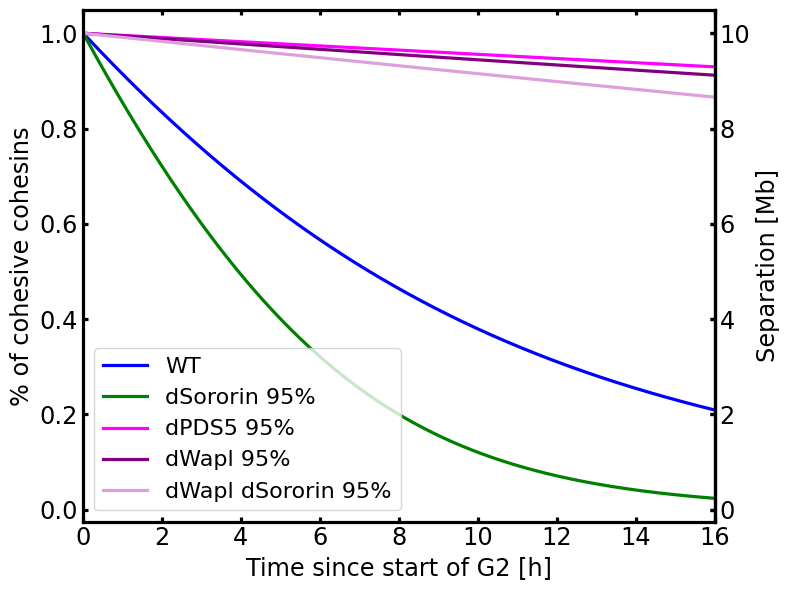

In [65]:
Model_WT_bound_RAD21 =  (parameter_dict[N_R] - Model_WT[:,8])/parameter_dict[N_R]

Model_dPDS5_bound_RAD21 = (parameter_dict[N_R] - Model_dPDS5[:,8])/parameter_dict[N_R]

Model_dSororin_bound_RAD21 = (parameter_dict[N_R] - Model_dSororin[:,8])/parameter_dict[N_R]

Model_dWapl_bound_RAD21 = (parameter_dict[N_R] - Model_dWapl[:,8])/parameter_dict[N_R]

Model_dWdS_bound_RAD21 = (parameter_dict[N_R] - Model_dWdS[:,8])/parameter_dict[N_R]

fig, ax1 = plt.subplots(figsize=(8, 6))
plt.rcParams['svg.fonttype']='none'
time = Model_WT[:, 0]/3600
ax1.plot(time, Model_WT_bound_RAD21, label='WT', color='blue', linestyle='solid')
ax1.plot(time, Model_dSororin_bound_RAD21, label='dSororin 95%', color='green', linestyle='solid')
ax1.plot(time, Model_dPDS5_bound_RAD21, label='dPDS5 95%', color='magenta', linestyle='solid')
ax1.plot(time, Model_dWapl_bound_RAD21, label='dWapl 95%', color='purple', linestyle='solid')
ax1.plot(time, Model_dWdS_bound_RAD21, label='dWapl dSororin 95%', color='plum', linestyle='solid')
ax1.set_xlim([time[0],time[-1]])
ax1.set_xlabel("Time since start of G2 [h]")
ax1.set_ylabel("% of cohesive cohesins")
ax1.legend(fontsize=16) 
# Create right y-axis
ax2 = ax1.twinx()
# Set the right y-axis limits to be 10x the left axis
ax2.set_ylim([y * 10 for y in ax1.get_ylim()])
ax2.set_ylabel('Separation [Mb]')
useLargeSize2(plt, ax1, ax2, marker_lines = None, fontsize = 'xx-large', fontproperties=None, LW=2.3)
plt.savefig("sisterCs_plot.svg", format='svg')

## dRAD21

In [104]:
parameter_dict_string_keys = {str(key): value for key, value in parameter_dict.items()}
print(parameter_dict_string_keys)
import tellurium as te

# Define ranges for K_SX (from S to X) and N_X
# N_S_values = np.logspace(-10, 0, 10)
N_R_values = [0.01,  0.1, 0.2, 0.3, 0.5, 1]
# Initialize an empty matrix to store bound_time values
bound_time_matrix = np.zeros(len(N_R_values))

for i, N_R_val in enumerate(N_R_values):
    # simulated WT five-state mode
    parameter_dict_string_keys["F_R_sister_initial"] = N_R_val
    model = build_model(model_coh, parameter_dict_string_keys)
    # Load the model
    r = te.loada(model)
    # Simulate the model
    r.simulate(0, 3600*6, 10000)
    bound_time1 = RAD21_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], B_W = r.RPW_conc, F_R_free=r.R_free_conc, N_R = parameter_dict[N_R])
    
    tau_W = Wapl_bound_time(K_RPW_RP = parameter_dict[K_RPW_RP], K_RPW_R_free = parameter_dict[K_RPW_R_free])
    fraction_W = Wapl_bound_fraction(tau_W = tau_W, K_RP_RPW = parameter_dict[K_RP_RPW], RP=r.RP_conc)

    tau_S = Sororin_bound_time(K_RPS_RP = parameter_dict[K_RPS_RP])
    fraction_S =  Sororin_bound_fraction(tau_S, K_RP_RPS=parameter_dict[K_RP_RPS], RP=r.RP_conc)

    tau_P = PDS5_bound_time(K_RPW_R_free = parameter_dict[K_RPW_R_free], K_RP_R = parameter_dict[K_RP_R], RP=r.RP_conc, W_bound=r.RPW_conc, P_bound=(r.RP_conc+r.RPW_conc+r.RPS_conc))
    fraction_P = PDS5_bound_fraction(tau_P = tau_P, K_R_RP = parameter_dict[K_R_RP], R = r.R_conc)
    
    print("Cohesin Bound Time: {}".format(bound_time1))
    print("Wapl Time: {}, Wapl Bound Fraction: {}".format(tau_W, fraction_W))
    print("Sororin Time: {}, Sororin Bound Fraction: {}".format(tau_S, fraction_S))
    print("PDS5 Time: {}, PDS5 Bound Fraction: {}".format(tau_P, fraction_P))

{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 36000, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219073226133673, 'K_RP_R': 0.156542785420589, 'K_RPW_R_free': 0.000314899608854888, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085077555383e-6, 'K_RPS_RP': 0.0100000000000000, 'K_R_RP': 1.80588143214753e-7, 'R_free_init': 0, 'R_init': 189646.666667, 'RPW_init': 0, 'RPS_init': 0, 'RP_init': 0, 'S_init': 79770, 'W_init': 53566.811760000004, 'P_init': 159436.0851}
{'tau_S': 100.0, 'F_S': 0.52, 'N_S': 79770, 'tau_W': 45.0, 'F_W': 0.15615101002232953, 'N_W': 53566.811760000004, 'tau_P': 72, 'F_P': 0.34295489045472055, 'N_P': 159436.0851, 'tau_R': 36000, 'F_R_sister': 0.5, 'N_R': 189646.666667, 'K_RPW_RP': 0.0219073226133673, 'K_RP_R': 0.156542785420589, 'K_RPW_R_free': 0.000314899608854888, 'K_RP_RPW': 8.50586292019298e-7, 'K_RP_RPS': 2.24085

## End